In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import (
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

In [10]:
data = load_breast_cancer()
X = data.data
y = data.target

print("Dataset shape:", X.shape)
print("Classes:", data.target_names)

# 80/20 Stratified Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training data: {X_train.shape}")
print(f"Testing data:  {X_test.shape}")

Dataset shape: (569, 30)
Classes: ['malignant' 'benign']
Training data: (455, 30)
Testing data:  (114, 30)


In [13]:
from sklearn.calibration import CalibratedClassifierCV

linear_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", CalibratedClassifierCV(
        estimator=SVC(kernel="linear", C=1.0, random_state=42),
        ensemble=False
    ))
])

# Train the model
linear_svm.fit(X_train, y_train)

# Make predictions
y_pred_linear = linear_svm.predict(X_test)

# Calculate prediction probabilities
y_prob_linear = linear_svm.predict_proba(X_test)[:, 1]

print("Linear SVM training and prediction completed.")

Linear SVM training and prediction completed.


In [14]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import CalibratedClassifierCV

# Create RBF SVM model
rbf_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", CalibratedClassifierCV(
        estimator=SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale",
            random_state=42
        ),
        ensemble=False
    ))
])

# Train the model
rbf_svm.fit(X_train, y_train)

# Make predictions
y_pred_rbf = rbf_svm.predict(X_test)

# Calculate prediction probabilities
y_prob_rbf = rbf_svm.predict_proba(X_test)[:, 1]

print("RBF SVM training and prediction completed.")

RBF SVM training and prediction completed.


In [15]:
def evaluate_model(name, y_test, y_pred, y_prob):
  print("\n" + "=" * 50)
  print(name)
  print("=" * 50)
  acc = accuracy_score(y_test, y_pred)
  prec = precision_score(y_test, y_pred)
  rec = recall_score(y_test, y_pred)
  f1 = f1_score(y_test, y_pred)
  auc = roc_auc_score(y_test, y_prob)

  print(f"Accuracy  : {acc:.4f}")
  print(f"Precision : {prec:.4f}")
  print(f"Recall    : {rec:.4f}")
  print(f"F1-score  : {f1:.4f}")
  print(f"ROC-AUC   : {auc:.4f}")
  print("\nClassification Report:")
  print(classification_report(y_test, y_pred, target_names=data.target_names))

  return {
      "Model": name,
      "Accuracy": acc,
      "Precision": prec,
      "Recall": rec,
      "F1-score": f1,
      "ROC-AUC": auc,
  }


linear_results = evaluate_model(
    "Linear SVM", y_test, y_pred_linear, y_prob_linear
)
rbf_results = evaluate_model("RBF Kernel SVM", y_test, y_pred_rbf, y_prob_rbf)


Linear SVM
Accuracy  : 0.9825
Precision : 0.9861
Recall    : 0.9861
F1-score  : 0.9861
ROC-AUC   : 0.9964

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


RBF Kernel SVM
Accuracy  : 0.9825
Precision : 0.9861
Recall    : 0.9861
F1-score  : 0.9861
ROC-AUC   : 0.9950

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [16]:
results_df = pd.DataFrame([linear_results, rbf_results])

print("\n--- Performance Comparison Table ---")
display(results_df.round(4))


--- Performance Comparison Table ---


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Linear SVM,0.9825,0.9861,0.9861,0.9861,0.9964
1,RBF Kernel SVM,0.9825,0.9861,0.9861,0.9861,0.9950


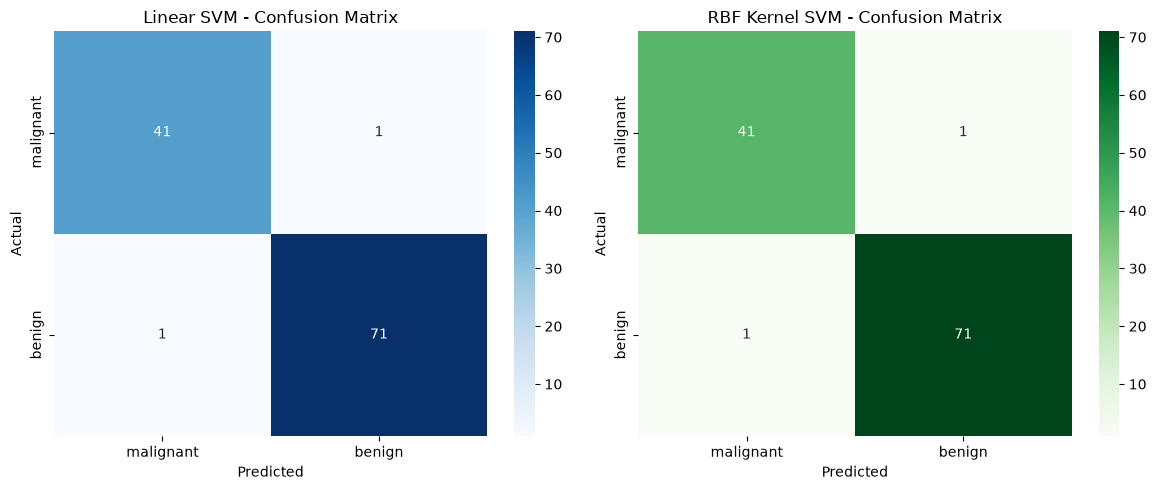

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_linear = confusion_matrix(y_test, y_pred_linear)
cm_rbf = confusion_matrix(y_test, y_pred_rbf)

sns.heatmap(
    cm_linear,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0],
    xticklabels=data.target_names,
    yticklabels=data.target_names,
)
axes[0].set_title("Linear SVM - Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    cm_rbf,
    annot=True,
    fmt="d",
    cmap="Greens",
    ax=axes[1],
    xticklabels=data.target_names,
    yticklabels=data.target_names,
)
axes[1].set_title("RBF Kernel SVM - Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

TypeError: RocCurveDisplay.from_predictions() got an unexpected keyword argument 'color'

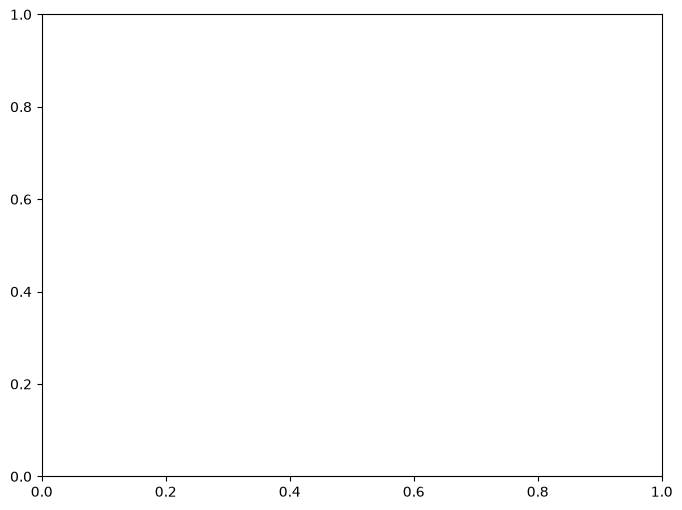

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

# Create the ROC curve plot
fig, ax = plt.subplots(figsize=(8, 6))

# ROC curve for Linear SVM
RocCurveDisplay.from_predictions(
    y_test,
    y_prob_linear,
    name="Linear SVM",
    ax=ax,
    color="blue"
)

# ROC curve for RBF SVM
RocCurveDisplay.from_predictions(
    y_test,
    y_prob_rbf,
    name="RBF Kernel SVM",
    ax=ax,
    color="green"
)

# Random classifier reference line
plt.plot(
    [0, 1], [0, 1],
    "k--",
    label="Random Chance (AUC = 0.50)"
)

# Add labels and title
plt.title("ROC Curves Comparison: Linear vs. RBF SVM")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()